# 09. モデルの軽量化・高速化：FP16・知識蒸留・INT8量子化・ONNX

**セミナー対応章**：第4章（2）　｜　**推奨ランタイム**：Colab無料枠 T4 GPU　｜　**所要時間**：約6分

工場のライン PC や Jetson などのエッジデバイスで動かすには、モデルを小さく・速くする必要があります。
1. 大きいモデル（Real-ESRGAN, 1670万パラメータ）と軽量モデル（Compact, 120万）の速度比較
2. **FP16（半精度）** で高速化
3. **知識蒸留**：大きいモデル（教師）の出力を小さいモデル（生徒）に真似させる
4. **ONNX 変換 + INT8 量子化**：PyTorch 不要のランタイムで CPU 推論（エッジ実装の第一歩）

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path + ".part")      # 途中で止めても壊れたファイルが残らないように
        os.replace(path + ".part", path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


In [2]:
if IN_COLAB:
    pip_install("onnx", "onnxruntime", "onnxscript")
import cv2
import spandrel
import torch.nn as nn

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def bench(fn, n=10):
    fn()                                                    # ウォームアップ
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(n):
        fn()
    if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / n * 1000                     # ms

## 1. 大きいモデル vs 軽量モデル、FP32 vs FP16

model                  prec        params  time(128->512)
Real-ESRGAN x4plus     FP32    16,697,987         48.1 ms
Real-ESRGAN x4plus     FP16    16,697,987         38.1 ms
Real-ESRGAN Compact    FP32     1,213,296          2.9 ms
Real-ESRGAN Compact    FP16     1,213,296          2.5 ms


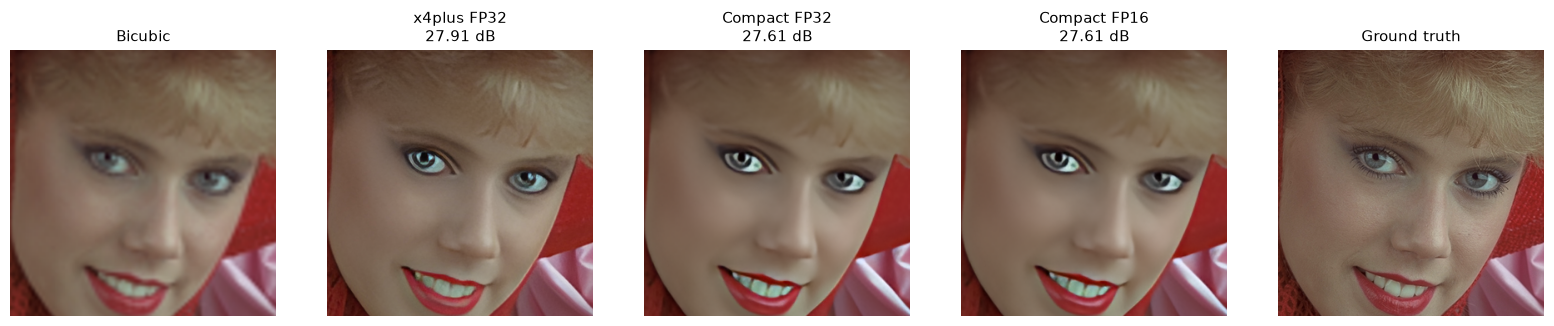

In [3]:
teacher = spandrel.ModelLoader().load_from_file(
    download("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth")).to(DEVICE).eval()
compact = spandrel.ModelLoader().load_from_file(
    download("https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.5.0/realesr-general-x4v3.pth")).to(DEVICE).eval()

hr = load_portrait()                          # 顔が大きく写った高画質画像（512x512）
lr = hr.resize((128, 128), Image.BICUBIC)
x = to_tensor(lr).to(DEVICE)

rows = []
with torch.no_grad():
    for name, m in [("Real-ESRGAN x4plus", teacher), ("Real-ESRGAN Compact", compact)]:
        rows.append((name, "FP32", n_params(m.model), bench(lambda: m(x))))
        if DEVICE == "cuda":
            m.model.half()
            rows.append((name, "FP16", n_params(m.model), bench(lambda: m(x.half()))))
            m.model.float()
print(f"{'model':22s} {'prec':5s} {'params':>12s} {'time(128->512)':>15s}")
for r in rows:
    print(f"{r[0]:22s} {r[1]:5s} {r[2]:12,d} {r[3]:12.1f} ms")

# 画質も確認する（速さだけでなく、結果の見た目が許容できるか）
with torch.no_grad():
    sr1 = {"x4plus FP32": tensor_to_pil(teacher(x)), "Compact FP32": tensor_to_pil(compact(x))}
    if DEVICE == "cuda":
        compact.model.half(); sr1["Compact FP16"] = tensor_to_pil(compact(x.half())); compact.model.float()
box = (110, 40, 430, 360)                     # 顔の部分を拡大
show([lr.resize(hr.size, Image.BICUBIC).crop(box)] + [v.crop(box) for v in sr1.values()] + [hr.crop(box)],
     ["Bicubic"] + [f"{n}\n{psnr(v, hr):.2f} dB" for n, v in sr1.items()] + ["Ground truth"], size=3.2)

## 2. 知識蒸留（Knowledge Distillation）
教師（Real-ESRGAN x4plus）の出力を「正解」として、パラメータ数 1/650 程度の小さな生徒ネットワークを学習します。
自社の画像（ラインカメラの画像など）で蒸留すれば、**その現場に特化した小型モデル** が作れます。

teacher params: 16,697,987   student params: 25,616


step 0: L1 to teacher 0.0495  (5s)


step 250: L1 to teacher 0.0240  (18s)


step 500: L1 to teacher 0.0192  (31s)


step 750: L1 to teacher 0.0216  (45s)


step 1000: L1 to teacher 0.0210  (59s)


step 1250: L1 to teacher 0.0210  (73s)


step 1500: L1 to teacher 0.0240  (86s)


step 1750: L1 to teacher 0.0187  (100s)


蒸留の学習時間: 113s


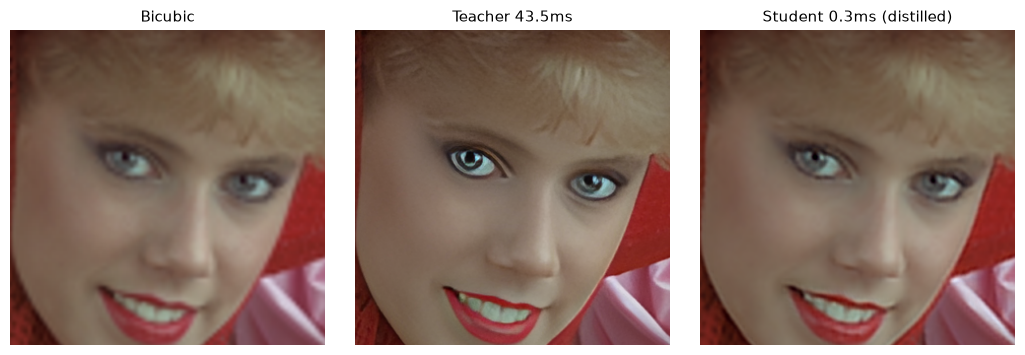

生徒は教師の 173 倍速。教師出力との PSNR: 30.63 dB


In [4]:
class TinySR(nn.Module):
    """3層の畳み込み + PixelShuffle による 4倍超解像（ESPCN 風）"""
    def __init__(self, c=32):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(3, c, 5, padding=2), nn.PReLU(c),
                                  nn.Conv2d(c, c, 3, padding=1), nn.PReLU(c),
                                  nn.Conv2d(c, 3 * 16, 3, padding=1))
        self.up = nn.PixelShuffle(4)
    def forward(self, x):
        base = nn.functional.interpolate(x, scale_factor=4, mode="bilinear", align_corners=False)
        return base + self.up(self.body(x))                    # 残差学習：補間との差だけ学ぶ

student = TinySR().to(DEVICE)
print(f"teacher params: {n_params(teacher.model):,}   student params: {n_params(student):,}")

# 学習データ：サンプル画像からランダムに切り出した低解像度パッチ（教師の出力が正解）
pool = [to_np(load_sample(n)) for n in ("astronaut", "coffee", "chelsea", "rocket")] + [to_np(hr)]
def random_lr_batch(bs=16, p=48):
    out = []
    for _ in range(bs):
        im = pool[np.random.randint(len(pool))]
        s = max(np.random.uniform(0.25, 0.5), (p + 1) / min(im.shape[:2]))
        small = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        y0, x0 = np.random.randint(0, small.shape[0] - p), np.random.randint(0, small.shape[1] - p)
        out.append(small[y0:y0 + p, x0:x0 + p])
    return torch.from_numpy(np.stack(out)).permute(0, 3, 1, 2).to(DEVICE)

opt = torch.optim.Adam(student.parameters(), 1e-3)
torch.backends.cudnn.benchmark = True                          # 毎回同じ大きさの入力なので、最速の計算方法を選ばせる
t = time.time()
for step in range(2000):
    xb = random_lr_batch()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
        target = teacher(xb).float()                           # 教師の出力。教師は FP16 で動かす（1. で見たとおり結果はほぼ同じで、T4 では数倍速い）
    loss = nn.functional.l1_loss(student(xb), target)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 250 == 0:
        print(f"step {step}: L1 to teacher {loss.item():.4f}  ({time.time()-t:.0f}s)")
print(f"蒸留の学習時間: {time.time()-t:.0f}s")
student.eval()

with torch.no_grad():
    out_t = tensor_to_pil(teacher(x))
    out_s = tensor_to_pil(student(x))
    t_ms, s_ms = bench(lambda: teacher(x)), bench(lambda: student(x))
bic = lr.resize(hr.size, Image.BICUBIC)
box = (110, 40, 430, 360)                     # 顔の部分を拡大
show([bic.crop(box), out_t.crop(box), out_s.crop(box)],
     ["Bicubic", f"Teacher {t_ms:.1f}ms", f"Student {s_ms:.1f}ms (distilled)"], size=3.5)
print(f"生徒は教師の {t_ms/s_ms:.0f} 倍速。教師出力との PSNR: {psnr(out_s, out_t):.2f} dB")

## 3. ONNX 変換と INT8 量子化（CPU推論）
ONNX にすると PyTorch なしで、ONNX Runtime・TensorRT（Jetson）・OpenVINO（Intel）などで動かせます。
INT8 量子化は重みと演算を 8bit 整数にして、**サイズ 1/4・CPU で高速化** を狙います（精度は少し落ちる）。

C:\Users\nagat\AppData\Local\Temp\ipykernel_1768\2901230348.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(student_cpu, dummy, "tiny_sr.onnx", input_names=["lr"], output_names=["sr"], opset_version=17,


ONNX FP32 (CPU)      101.6 KB      8.6 ms  PSNR vs teacher 30.63 dB


ONNX INT8 (CPU)       33.6 KB      8.2 ms  PSNR vs teacher 30.59 dB


PyTorch FP32 (CPU)                49.0 ms


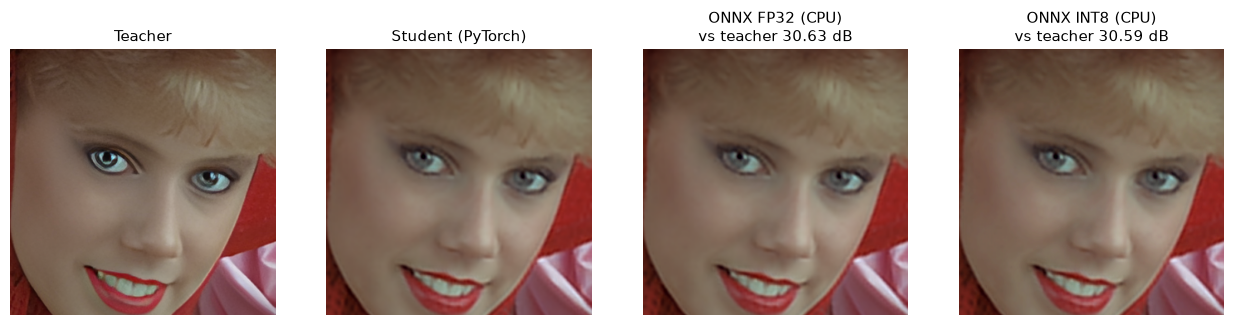

In [5]:
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat

assert "out_t" in globals(), "2. の蒸留が最後まで実行されていません（途中で止めた場合は、2. のセルをもう一度実行してください）"
student_cpu = TinySR().eval()
student_cpu.load_state_dict({k: v.cpu() for k, v in student.state_dict().items()})
dummy = torch.zeros(1, 3, 128, 128)
torch.onnx.export(student_cpu, dummy, "tiny_sr.onnx", input_names=["lr"], output_names=["sr"], opset_version=17,
                  dynamo=False)

class Calib(CalibrationDataReader):
    """量子化のスケールを決めるための代表データ（実運用では現場の画像を数十枚）"""
    def __init__(self):
        self.data = iter([{"lr": random_lr_batch(1, 128).cpu().numpy()} for _ in range(16)])
    def get_next(self):
        return next(self.data, None)

ort.quantization.shape_inference.quant_pre_process("tiny_sr.onnx", "tiny_sr_prep.onnx")
quantize_static("tiny_sr_prep.onnx", "tiny_sr_int8.onnx", Calib(), quant_format=QuantFormat.QDQ,
                weight_type=QuantType.QInt8, activation_type=QuantType.QUInt8)

inp = {"lr": to_tensor(lr).numpy()}
res = {}
for name, path in [("ONNX FP32 (CPU)", "tiny_sr.onnx"), ("ONNX INT8 (CPU)", "tiny_sr_int8.onnx")]:
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    out = sess.run(None, inp)[0]
    ms = bench(lambda: sess.run(None, inp), n=20)
    res[name] = to_pil(out[0].transpose(1, 2, 0))
    print(f"{name:18s} {os.path.getsize(path)/1024:7.1f} KB  {ms:7.1f} ms  PSNR vs teacher {psnr(res[name], out_t):.2f} dB")
with torch.no_grad():
    print(f"{'PyTorch FP32 (CPU)':18s} {'':7s}     {bench(lambda: student_cpu(torch.from_numpy(inp['lr']))):7.1f} ms")
show([out_t.crop(box), out_s.crop(box)] + [v.crop(box) for v in res.values()],
     ["Teacher", "Student (PyTorch)"] + [f"{n}\nvs teacher {psnr(v, out_t):.2f} dB" for n, v in res.items()], size=3.2)

**観察ポイント**：INT8 でファイルサイズは約 1/3 になります。速度は **CPU の種類やモデルの大きさで変わり**、このような小さいモデルでは速くならないこともあります（量子化・逆量子化の処理が相対的に重い）。
大きなモデルや INT8 演算に強いハードウェア（NPU, TensorRT on Jetson）で効果が出やすいです。**軽量化は必ず実機で実測** してください。

## まとめ：軽量化の手段
| 手段 | 効果 | 注意点 |
|---|---|---|
| 軽量アーキテクチャの選択 | 数倍〜数十倍速 | 画質は少し落ちる |
| FP16 / BF16 | GPUで約2倍速・メモリ半分 | 一部モデルで数値不安定 |
| 知識蒸留 | 現場特化の小型モデル | 教師の誤り（ハルシネーション）も継承 |
| INT8 量子化 | サイズ1/4・CPU/NPUで高速 | キャリブレーションデータが重要 |
| ONNX / TensorRT 変換 | フレームワーク非依存・最適化 | 対応していない演算がある |
| 拡散モデルのステップ削減（LCM, Turbo, 1ステップ蒸留） | 数十倍速 | 品質・多様性とのトレードオフ |

**Jetson での実装例**：PyTorch → ONNX → `trtexec --onnx=tiny_sr.onnx --fp16`（TensorRT エンジン化）